# Oilfield ML laboratory: logs, telemetry, predictions

**A worked study, separate from `interview_starter.ipynb`.** All data already lives in `data/`; no downloads, credentials or cloud writes are needed. Run All with `main/.venv`. Saved outputs let you study without training again.

**20-minute reading route:** 0–3 min: §§1–2 (question/data/split); 3–8: §§3–5 (preprocessing/models/tuning); 8–12: §§6–7 (evaluation/explanations); 12–16: §§8–9 (time-series features/clusters/replay); 16–20: §§10–12 (regression/persistence/production). Read code details and optional cloud cells later.

Two different tasks prevent misleading claims:
- **FORCE well logs:** predict **sandstone (code 30000) vs other recorded lithologies**. This is an instructional binary reduction of a multiclass benchmark, not a reservoir-quality or production forecast. Three wells train, a fourth validates, a fifth tests.
- **3W production telemetry:** discriminate normal vs severe-slugging windows and inspect shapes. Only two recordings from **one well** are present. Recording/date is confounded with class: even perfect scores are only a workflow demonstration.

Volve wireline curves add acquisition-quality context. Casing records provide completion context, not per-sample labels. Provenance and units: [data/README.md](data/README.md). **Depth is not time.** Do not describe these logs as a live feed.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, itertools, math, importlib.metadata, importlib.util
ROOT = Path.cwd().resolve()
if not (ROOT / 'ThreeWToolkit').is_dir():
    ROOT = ROOT / 'main'
assert (ROOT / 'ThreeWToolkit').is_dir(), 'Open this notebook from main/'
assert Path(sys.prefix).resolve() == (ROOT / '.venv').resolve(), 'Choose the main/.venv kernel'
os.chdir(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
os.environ.setdefault('OMP_NUM_THREADS', '2')
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.cache/matplotlib'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
import torch, joblib
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.model_selection import GroupKFold, ParameterSampler
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, matthews_corrcoef, roc_auc_score, average_precision_score,
    confusion_matrix, RocCurveDisplay, PrecisionRecallDisplay, r2_score, mean_absolute_error)
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from ThreeWToolkit.core import BaseDataset, DatasetOutputs
from ThreeWToolkit.models import SklearnModelsConfig, MLPConfig
from ThreeWToolkit.trainer import SklearnTrainerConfig, TorchTrainerConfig
from ThreeWToolkit.assessment import ModelAssessmentConfig
from ThreeWToolkit.utils import ModelRecorder
from ThreeWToolkit.data_visualization import PlotSeries, CorrelationHeatmap
SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED); torch.set_num_threads(2)
sns.set_theme(style='whitegrid', context='notebook')
ART = ROOT / '.cache/oilfield_ml'; ART.mkdir(parents=True, exist_ok=True)

def showplot(name):
    plt.gcf().tight_layout()
    plt.gcf().savefig(ART / f'{name}.png', dpi=110, bbox_inches='tight')
    plt.show(); plt.close('all')

class FrameDataset(BaseDataset):
    def __init__(self, events): self.events = events
    def __len__(self): return len(self.events)
    def __getitem__(self, index): return self.events[index]

def frames(X, y=None, name='tabular'):
    return FrameDataset([DatasetOutputs(signal=pd.DataFrame(X).reset_index(drop=True),
        label=None if y is None else pd.Series(np.asarray(y), dtype='int64'),
        metadata={'event_id': name, 'event_type': 'real'})])

print('Shared environment:', sys.version.split()[0])
display(pd.Series({p: importlib.metadata.version(p) for p in ['numpy','pandas','scikit-learn','torch']}, name='version'))

Shared environment: 3.14.6


numpy            2.5.4
pandas           2.3.3
scikit-learn     1.9.1
torch           2.14.1
Name: version, dtype: object

## 1. What are the observations?
A FORCE row is one depth sample with log measurements. GR is gamma ray (gAPI), RHOB bulk density (g/cm³), NPHI neutron porosity (fraction), DTC sonic slowness (µs/ft), RDEP deep resistivity (ohm m), CALI caliper (in), SP spontaneous potential (mV). Verify supplied units before adapting to another vendor.

A 3W row is timestamped process telemetry. **P-TPT** is subsea Christmas-tree pressure (Pa); T-TPT temperature (°C). The 3W chart is a dataset viewer, not an algorithm. The label `class` describes an operating condition; unlabeled periods remain unlabeled.

In [2]:
logs = pd.read_parquet(ROOT / 'data/force2020_logs.parquet').sort_values(['WELL','DEPTH_MD'])
telemetry = pd.read_parquet(ROOT / 'data/threew_real_events.parquet').sort_values(['source_file','timestamp'])
wireline = pd.read_csv(ROOT / 'data/volve_wireline_gr.csv')
ccl = pd.read_csv(ROOT / 'data/volve_wireline_ccl.csv')
casing = pd.read_csv(ROOT / 'data/force2020_casing.csv')
LABEL = 'FORCE_2020_LITHOFACIES_LITHOLOGY'
FEATURES = ['GR','RHOB','NPHI','DTC','RDEP','CALI','SP']
assert logs['id'].is_unique and telemetry['id'].is_unique
assert logs[LABEL].notna().all()
logs['sandstone'] = (logs[LABEL] == 30000).astype('int64')
display(pd.DataFrame({'rows':[len(logs),len(telemetry),len(wireline),len(ccl),len(casing)],
    'grain':['well/depth','instance/time','GR frame/depth','CCL frame/depth','casing surface']},
    index=['FORCE','3W','Volve GR','Volve CCL','FORCE casing']))
print('Unlabeled 3W rows:', int(telemetry['class'].isna().sum()))
print('Volve GR entirely missing curves:', wireline.columns[wireline.isna().all()].tolist())
print('Do not join the two Volve frames by row number; their depth sampling differs.')

Unlabeled 3W rows: 7200
Volve GR entirely missing curves: ['FCD']
Do not join the two Volve frames by row number; their depth sampling differs.


,rows,grain
FORCE,58694,well/depth
3W,43050,instance/time
Volve GR,1245,GR frame/depth
Volve CCL,6780,CCL frame/depth
FORCE casing,285,casing surface


## 2. Split first, then inspect training data
Random depth-row splitting leaks nearby geology across the boundary. We hold out entire wells. `id`, WELL, location, formation, confidence, and lithology code never enter the predictors. Feature choice is fixed before seeing test metrics. Training/validation are thinned every fifth depth sample for laptop speed; the test well is evaluated in full. Correlated neighboring depths are still not independent observations.

,split,rows,wells,sandstone_fraction
0,train,7545,"15/9-13, 15/9-15, 16/1-2",0.167793
1,validation,3470,15/9-17,0.132565
2,test,3623,16/1-6 A,0.076180


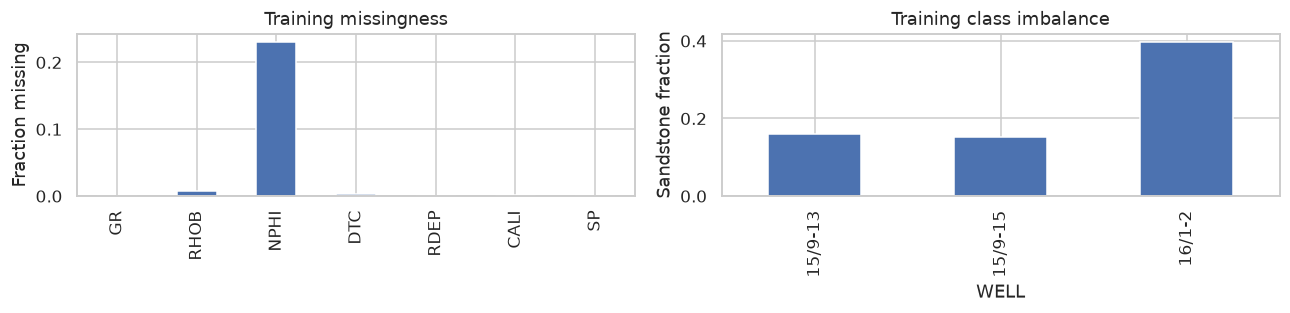

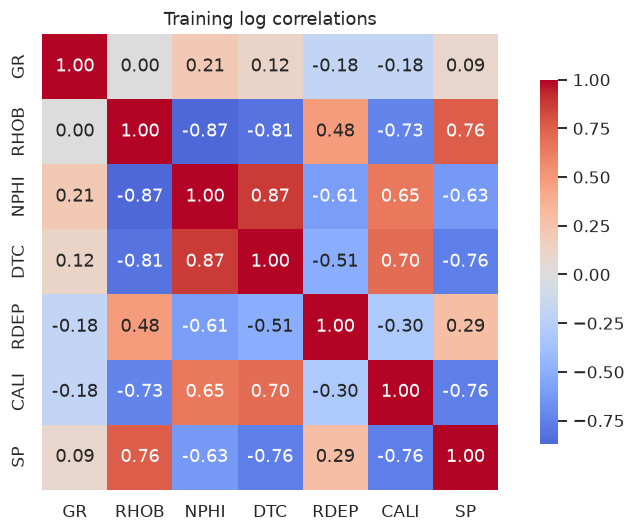

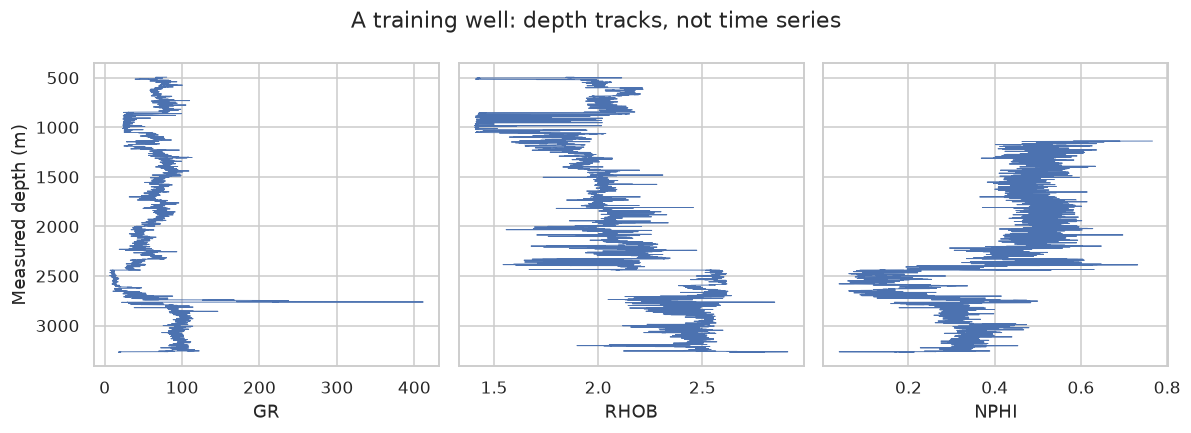

In [3]:
TRAIN_WELLS = ['15/9-13','15/9-15','16/1-2']
VAL_WELLS = ['15/9-17']; TEST_WELLS = ['16/1-6 A']
def subset(wells, stride=1):
    return pd.concat([logs[logs.WELL.eq(w)].iloc[::stride] for w in wells]).copy()
train = subset(TRAIN_WELLS, 5); val = subset(VAL_WELLS, 5); test = subset(TEST_WELLS)
assert not (set(train.WELL) & set(val.WELL) or set(train.WELL) & set(test.WELL) or set(val.WELL) & set(test.WELL))
Xtr, Xva, Xte = (d[FEATURES].replace([np.inf,-np.inf],np.nan) for d in [train,val,test])
ytr, yva, yte = (d.sandstone.to_numpy() for d in [train,val,test])
display(pd.DataFrame([{'split':n,'rows':len(d),'wells':', '.join(d.WELL.unique()),
    'sandstone_fraction':d.sandstone.mean()} for n,d in [('train',train),('validation',val),('test',test)]]))
fig, ax = plt.subplots(1,2,figsize=(12,3))
Xtr.isna().mean().plot.bar(ax=ax[0], title='Training missingness', ylabel='Fraction missing')
train.groupby('WELL').sandstone.mean().plot.bar(ax=ax[1], title='Training class imbalance', ylabel='Sandstone fraction')
showplot('01_missingness_and_balance')
CorrelationHeatmap(Xtr, title='Training log correlations', figsize=(8,5)).plot()
showplot('02_correlations')
fig, ax = plt.subplots(1,3,figsize=(11,4), sharey=True)
well = train[train.WELL.eq(TRAIN_WELLS[0])]
for a,c in zip(ax,['GR','RHOB','NPHI']): a.plot(well[c],well.DEPTH_MD,linewidth=.6); a.set_xlabel(c)
ax[0].invert_yaxis(); ax[0].set_ylabel('Measured depth (m)')
fig.suptitle('A training well: depth tracks, not time series'); showplot('03_depth_tracks')

## 3. Preprocessing and a baseline
Missing values are retained until a training-fitted median imputer. Missingness indicators preserve availability information. StandardScaler uses training mean/std. Toolkit `NormalizeConfig(norm='l2')` likewise centers each column and scales by training population dispersion plus epsilon; its other norms change the dispersion measure. It must be fitted first. The full sklearn Pipeline is serialized, ensuring identical inference preprocessing. Extreme readings are inspected, not blindly deleted: an anomaly may be the signal we need.

We compare a majority baseline, logistic regression and a random forest through the actual toolkit `SklearnTrainerConfig`. The toolkit's sklearn `history.train_loss` stores estimator **score**, not a loss curve; do not plot it as neural-network loss.

In [4]:
def make_pipeline(estimator):
    return Pipeline([('impute',SimpleImputer(strategy='median',add_indicator=True)),
                     ('scale',StandardScaler()),('model',estimator)])
models = {}; training = {}; validation_prob = {}
configs = {
    'majority': DummyClassifier(strategy='prior'),
    'logistic': LogisticRegression(C=.3,class_weight='balanced',max_iter=600,random_state=SEED),
    'forest': RandomForestClassifier(n_estimators=100,max_depth=9,min_samples_leaf=8,
                                    class_weight='balanced',random_state=SEED,n_jobs=2)}
for name, estimator in configs.items():
    pipeline = make_pipeline(estimator)
    trainer = SklearnTrainerConfig(config_model=SklearnModelsConfig(
        model_type=Pipeline, model_params={'steps':pipeline.steps}), seed=SEED,n_jobs=2).build()
    # Toolkit sets integer verbosity; sklearn Pipeline requires a boolean.
    trainer.model.set_params(verbose=False)
    result = trainer.train(frames(Xtr,ytr),frames(Xva,yva))
    models[name] = result.model.model
    training[name] = (trainer,result)
    validation_prob[name] = models[name].predict_proba(Xva.to_numpy())[:,1]

def metrics(y,p,threshold=.5):
    pred = (p >= threshold).astype(int)
    return {'accuracy':accuracy_score(y,pred),'balanced_accuracy':balanced_accuracy_score(y,pred),
        'precision':precision_score(y,pred,zero_division=0),'recall_sensitivity':recall_score(y,pred,zero_division=0),
        'f1':f1_score(y,pred,zero_division=0),'MCC':matthews_corrcoef(y,pred),
        'ROC_AUC':roc_auc_score(y,p),'average_precision':average_precision_score(y,p)}
display(pd.DataFrame({n:metrics(yva,p) for n,p in validation_prob.items()}).T.round(3))
display(pd.DataFrame({'missing_training_rows':Xtr.isna().sum(),
    'fitted_training_median':models['forest'].named_steps['impute'].statistics_},index=FEATURES))
assert np.isfinite(models['forest'].named_steps['impute'].transform(Xva.to_numpy())).all()

,accuracy,balanced_accuracy,precision,recall_sensitivity,f1,MCC,ROC_AUC,average_precision
majority,0.867,0.500,0.000,0.000,0.000,0.000,0.500,0.133
logistic,0.641,0.743,0.254,0.883,0.394,0.331,0.820,0.368
forest,0.841,0.881,0.452,0.935,0.609,0.579,0.952,0.855


,missing_training_rows,fitted_training_median
GR,0,64.910461
RHOB,59,2.055585
NPHI,1741,0.438119
DTC,18,140.422455
RDEP,0,1.216092
CALI,17,13.794740
SP,0,67.548981


## 4. Tune without using the test well
Six small trials compare forest depth/leaf size on **GroupKFold across the three training wells**. Each fold refits its imputer/scaler. Optimize average precision (AP) because sandstone is the minority; AP measures ranking, not probability calibration. Optuna is used if installed; otherwise seeded sklearn ParameterSampler runs the same search space. The notebook prints which actually ran. Three wells are very limited cross-validation evidence.

sklearn ParameterSampler (Optuna unavailable)


,min_samples_leaf,max_depth,mean_AP,fold_AP
0,12,12,0.691748,"[0.846040284647526, 0.7704734931716168, 0.4587..."
1,12,4,0.660581,"[0.8753982882148803, 0.6265442861059954, 0.479..."
2,30,8,0.696044,"[0.8859636325121028, 0.72549725709856, 0.47667..."
3,4,4,0.657131,"[0.8752465508205991, 0.6297637594431484, 0.466..."
4,30,12,0.692000,"[0.8877333630041833, 0.7130276985909835, 0.475..."
5,30,4,0.657008,"[0.8597480318523214, 0.637947636428086, 0.4733..."


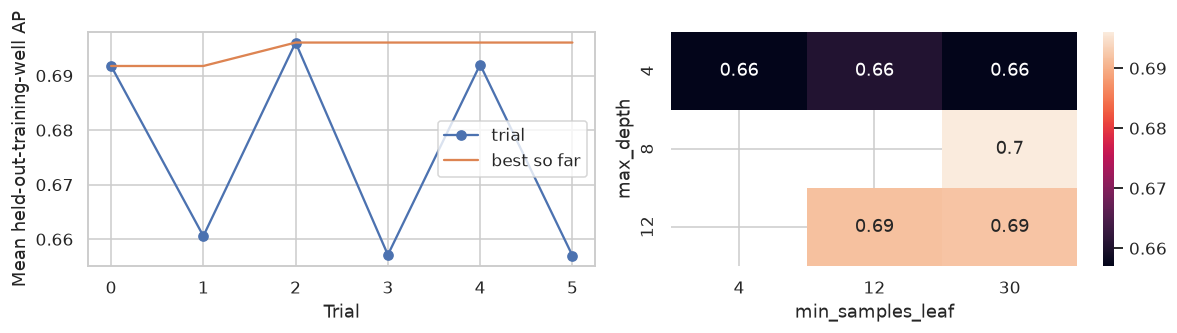

In [5]:
cv = list(GroupKFold(n_splits=3).split(Xtr,ytr,groups=train.WELL))
trials = []
def score_params(params):
    pipe = make_pipeline(RandomForestClassifier(n_estimators=60,random_state=SEED,n_jobs=2,
                            class_weight='balanced',**params))
    scores=[]
    for a,b in cv:
        fitted=clone(pipe).fit(Xtr.iloc[a],ytr[a])
        scores.append(average_precision_score(ytr[b],fitted.predict_proba(Xtr.iloc[b])[:,1]))
    trials.append({**params,'mean_AP':float(np.mean(scores)),'fold_AP':scores})
    return float(np.mean(scores))
if importlib.util.find_spec('optuna'):
    import optuna
    study=optuna.create_study(direction='maximize',sampler=optuna.samplers.TPESampler(seed=SEED))
    def objective(trial):
        return score_params({'max_depth':trial.suggest_categorical('max_depth',[4,8,12]),
                             'min_samples_leaf':trial.suggest_categorical('min_samples_leaf',[4,12,30])})
    study.optimize(objective,n_trials=6)
    tuning_engine='Optuna TPE'
else:
    for params in ParameterSampler({'max_depth':[4,8,12],'min_samples_leaf':[4,12,30]},n_iter=6,random_state=SEED):
        score_params(params)
    tuning_engine='sklearn ParameterSampler (Optuna unavailable)'
trial_table=pd.DataFrame(trials)
best=trials[int(trial_table.mean_AP.argmax())]
models['forest_tuned']=make_pipeline(RandomForestClassifier(n_estimators=100,random_state=SEED,n_jobs=2,
    class_weight='balanced',max_depth=int(best['max_depth']),min_samples_leaf=int(best['min_samples_leaf']))).fit(Xtr.to_numpy(),ytr)
validation_prob['forest_tuned']=models['forest_tuned'].predict_proba(Xva.to_numpy())[:,1]
print(tuning_engine); display(trial_table)
fig,ax=plt.subplots(1,2,figsize=(11,3))
ax[0].plot(trial_table.mean_AP,'o-',label='trial');ax[0].plot(trial_table.mean_AP.cummax(),label='best so far')
ax[0].set(xlabel='Trial',ylabel='Mean held-out-training-well AP');ax[0].legend()
sns.heatmap(trial_table.pivot_table(index='max_depth',columns='min_samples_leaf',values='mean_AP'),annot=True,ax=ax[1])
showplot('04_tuning')

## 5. Neural network: multilayer perceptron (MLP)
An MLP is a feed-forward network: numeric features → 32 ReLU units → 16 ReLU units → two class logits. Adam updates weights using cross-entropy gradients. Learning rate and architecture are **hyperparameters**; weights are learned parameters. This is not an LSTM and does not remember previous rows. Here training lasts 12 epochs on CPU, with a separate validation-loss curve. A serious search would tune epochs/regularization using development wells only.

Portable sklearn champion selected on validation AP: forest
MLP is a separately assessed research candidate; production example uses the portable sklearn pipeline.


Training: 100%|##########| 12/12 [00:00<00:00, 13.99epoch/s, loss=0.1386, val_loss=0.8616]


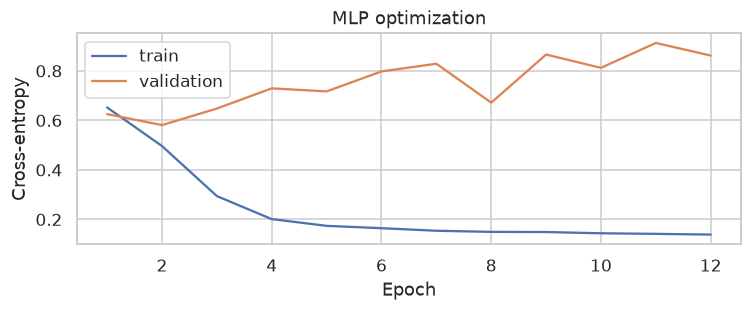

,accuracy,balanced_accuracy,precision,recall_sensitivity,f1,MCC,ROC_AUC,average_precision
majority,0.867,0.500,0.000,0.000,0.000,0.000,0.500,0.133
logistic,0.641,0.743,0.254,0.883,0.394,0.331,0.820,0.368
forest,0.841,0.881,0.452,0.935,0.609,0.579,0.952,0.855
forest_tuned,0.836,0.878,0.444,0.935,0.602,0.571,0.943,0.846
MLP,0.599,0.727,0.235,0.902,0.373,0.308,0.908,0.763


In [6]:
# Reuse preprocessing fitted on training data only; never fit on val/test.
neural_pre = Pipeline([('impute',SimpleImputer(strategy='median',add_indicator=True)),('scale',StandardScaler())])
Ztr=neural_pre.fit_transform(Xtr); Zva=neural_pre.transform(Xva); Zte=neural_pre.transform(Xte)
neural = TorchTrainerConfig(config_model=MLPConfig(hidden_sizes=(32,16),output_size=2,
    activation_function=torch.nn.ReLU()),epochs=12,batch_size=256,learning_rate=.002,
    device='cpu',deterministic=True,seed=SEED,use_class_weights=True).build()
neural_result=neural.train(frames(Ztr,ytr),frames(Zva,yva))
validation_prob['MLP']=neural.predict_proba(frames(Zva,yva)).y_pred[:,1]
fig,ax=plt.subplots(figsize=(7,3))
ax.plot(np.arange(1,13),neural_result.history.train_loss,label='train')
ax.plot(np.arange(1,13),neural_result.history.val_loss,label='validation')
ax.set(xlabel='Epoch',ylabel='Cross-entropy',title='MLP optimization');ax.legend();showplot('05_neural_loss')
validation_table=pd.DataFrame({n:metrics(yva,p) for n,p in validation_prob.items()}).T
# Freeze the portable sklearn champion before any test evaluation.
champion_name=max(models,key=lambda n:average_precision_score(yva,validation_prob[n]))
champion=models[champion_name]
print('Portable sklearn champion selected on validation AP:',champion_name)
print('MLP is a separately assessed research candidate; production example uses the portable sklearn pipeline.')
display(validation_table.round(3))

## 6. Evaluate once on the untouched well
Accuracy can hide minority failures. Sensitivity is recall = TP/(TP+FN). Precision asks whether alerts are trustworthy. Balanced accuracy averages class recalls; F1 balances precision/recall; MCC is a correlation-like **metric, not a significance test**. ROC AUC uses scores across thresholds; PR/AP is sensitive to prevalence. R² belongs to regression (later).

Threshold 0.5 is fixed here, not optimized on test labels. Operational alert costs can justify choosing another threshold on validation data. The reliability diagram checks calibration. A poor test result is useful evidence of domain shift, not something to hide or tune away.

Toolkit assessment (F1 uses toolkit weighted averaging): {'accuracy': 0.9378967706320729, 'balanced_accuracy': 0.9165216092282511, 'f1': 0.944257807518597}


,accuracy,balanced_accuracy,precision,recall_sensitivity,f1,MCC,ROC_AUC,average_precision
majority,0.924,0.500,0.000,0.000,0.000,0.000,0.500,0.076
logistic,0.948,0.865,0.627,0.768,0.691,0.666,0.936,0.831
forest,0.938,0.917,0.558,0.891,0.686,0.676,0.978,0.896
forest_tuned,0.928,0.913,0.516,0.895,0.654,0.647,0.978,0.898
MLP,0.817,0.886,0.290,0.967,0.446,0.470,0.970,0.895


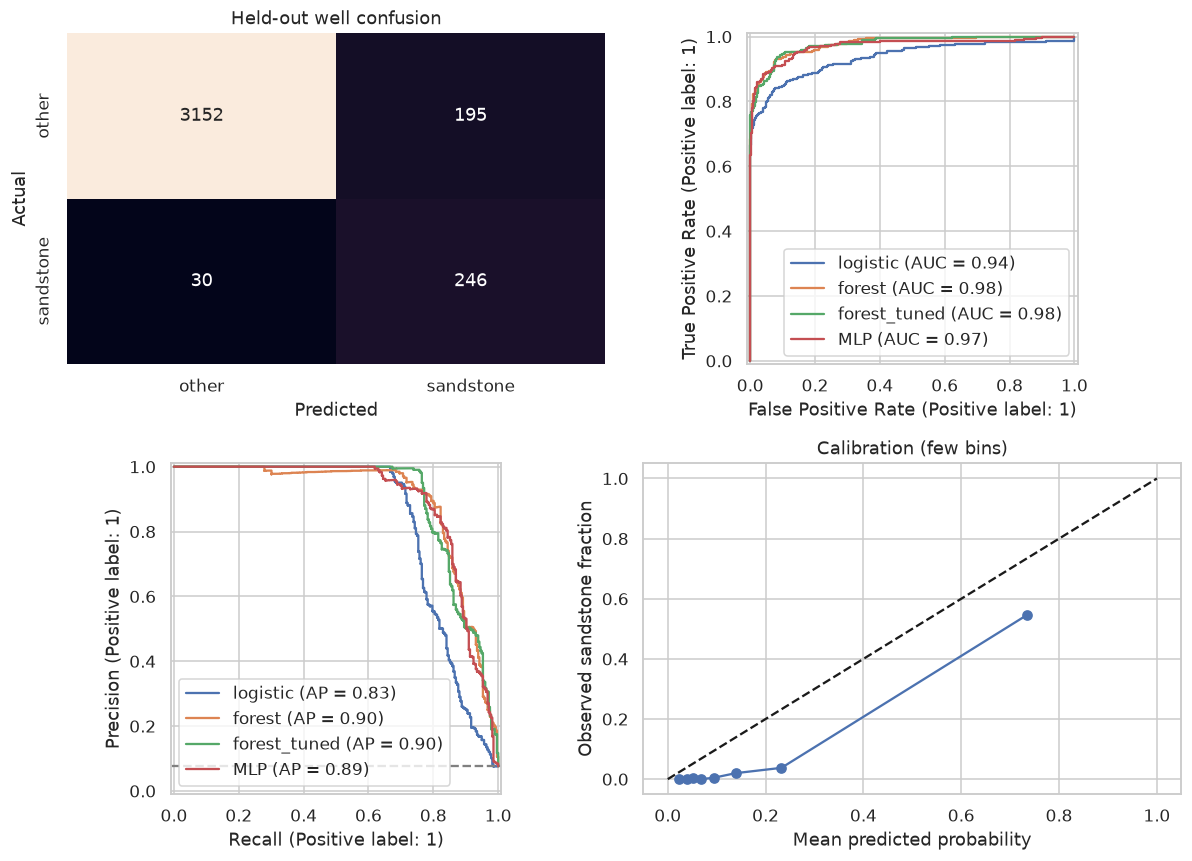

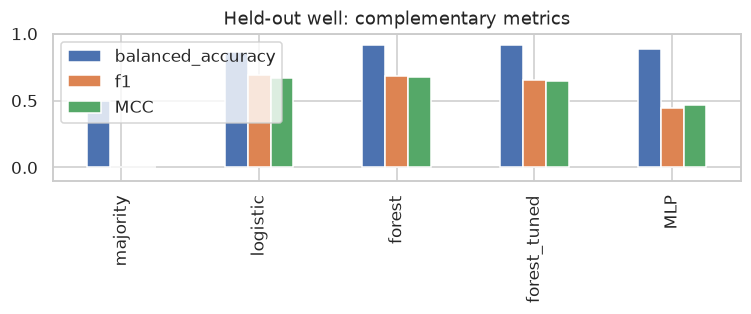

**Read this result:** forest finds 246 of 276 sandstone rows, but produces 195 false positives. Precision is 55.8%; sensitivity is 89.1%. A high AUC does not imply calibrated probabilities or a suitable operational threshold.

In [7]:
test_prob={n:m.predict_proba(Xte.to_numpy())[:,1] for n,m in models.items()}
test_prob['MLP']=neural.predict_proba(frames(Zte,yte)).y_pred[:,1]
test_table=pd.DataFrame({n:metrics(yte,p) for n,p in test_prob.items()}).T
p_test=test_prob[champion_name]; pred_test=(p_test>=.5).astype(int)
display(test_table.round(3))
fig,ax=plt.subplots(2,2,figsize=(11,8))
sns.heatmap(confusion_matrix(yte,pred_test),annot=True,fmt='d',cbar=False,ax=ax[0,0],
    xticklabels=['other','sandstone'],yticklabels=['other','sandstone'])
ax[0,0].set(xlabel='Predicted',ylabel='Actual',title='Held-out well confusion')
for n,p in test_prob.items():
    if n!='majority':
        RocCurveDisplay.from_predictions(yte,p,name=n,ax=ax[0,1])
        PrecisionRecallDisplay.from_predictions(yte,p,name=n,ax=ax[1,0])
ax[1,0].axhline(yte.mean(),color='gray',linestyle='--',label='prevalence')
obs,prob=calibration_curve(yte,p_test,n_bins=8,strategy='quantile')
ax[1,1].plot(prob,obs,'o-');ax[1,1].plot([0,1],[0,1],'k--')
ax[1,1].set(xlabel='Mean predicted probability',ylabel='Observed sandstone fraction',title='Calibration (few bins)')
showplot('06_test_diagnostics')
fig,ax=plt.subplots(figsize=(7,3));test_table[['balanced_accuracy','f1','MCC']].plot.bar(ax=ax)
ax.set_ylim(-.1,1);ax.set_title('Held-out well: complementary metrics');showplot('07_model_comparison')
# Toolkit assessment on the fixed forest: labels only, no probability metrics here.
forest_trainer,forest_result=training['forest']
assessment=ModelAssessmentConfig(metrics=['accuracy','balanced_accuracy','f1'],
    output_dir=ART/'assessment',export_results=True,generate_report=False).build()
assessed=assessment.evaluate(forest_result,forest_trainer.predict(frames(Xte,yte)))
print('Toolkit assessment (F1 uses toolkit weighted averaging):',assessed.metrics)
tn,fp,fn,tp=confusion_matrix(yte,pred_test).ravel()
display(Markdown(f'**Read this result:** {champion_name} finds {tp} of {tp+fn} sandstone rows, '
    f'but produces {fp} false positives. Precision is {tp/(tp+fp):.1%}; sensitivity is {tp/(tp+fn):.1%}. '
    'A high AUC does not imply calibrated probabilities or a suitable operational threshold.'))

### Uncertainty and model comparisons
The independent unit is a well, not a row. One final test well cannot estimate across-well uncertainty. Below is a **contiguous-depth block bootstrap**: an illustrative within-well interval with a chosen 200-row block length. It is not a guarantee for new wells. Sensitivity to block size matters.

A Friedman test compares paired model ranks across multiple independent datasets; the **Iman–Davenport** correction improves its approximation. We do not claim significance from one test well or two 3W recordings. For defensible model comparison collect more wells, use nested grouped evaluation, retain one score per held-out well, then consider paired tests and multiplicity correction. MCC is unrelated to this test.

Illustrative within-well ROC AUC block interval: [0.955 0.991]


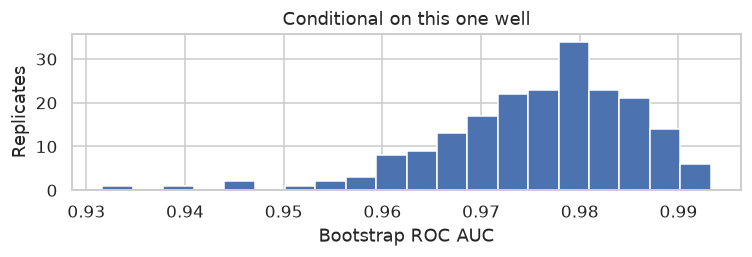

In [8]:
rng=np.random.default_rng(SEED); block=200
blocks=[np.arange(i,min(i+block,len(yte))) for i in range(0,len(yte),block)]
boot=[]
for _ in range(200):
    idx=np.concatenate([blocks[i] for i in rng.integers(0,len(blocks),len(blocks))])
    if len(np.unique(yte[idx]))==2: boot.append(roc_auc_score(yte[idx],p_test[idx]))
print('Illustrative within-well ROC AUC block interval:',np.quantile(boot,[.025,.975]).round(3))
fig,ax=plt.subplots(figsize=(7,2.5));ax.hist(boot,bins=20)
ax.set(xlabel='Bootstrap ROC AUC',ylabel='Replicates',title='Conditional on this one well');showplot('08_uncertainty')

## 7. Explain behavior, not just scores
Permutation importance measures the decrease in validation AP when a feature is shuffled. Correlated logs can mask each other's importance; row shuffling is a diagnostic, not a physical experiment.

The next cell computes **exact Shapley values for an empirical interventional game** on seven raw features of the logistic pipeline. For every subset, missing features are replaced by values from 16 training background rows. All 128 coalitions are evaluated: contributions sum to prediction minus baseline. This is SHAP analysis without requiring the unavailable `shap` library; it is exact for this small background game, not for the population. It explains the logistic model, **not necessarily the selected champion**. Correlated-feature combinations may be unrealistic, and explanations are not causal.

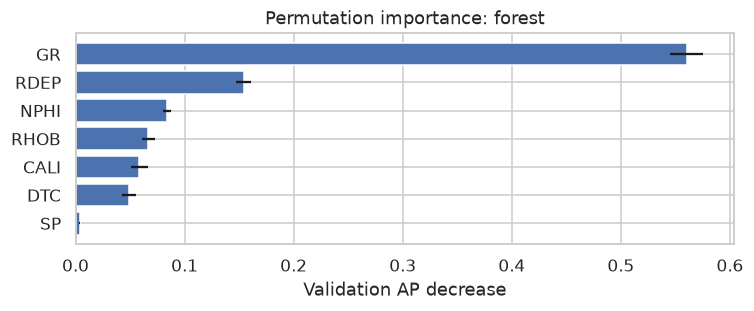

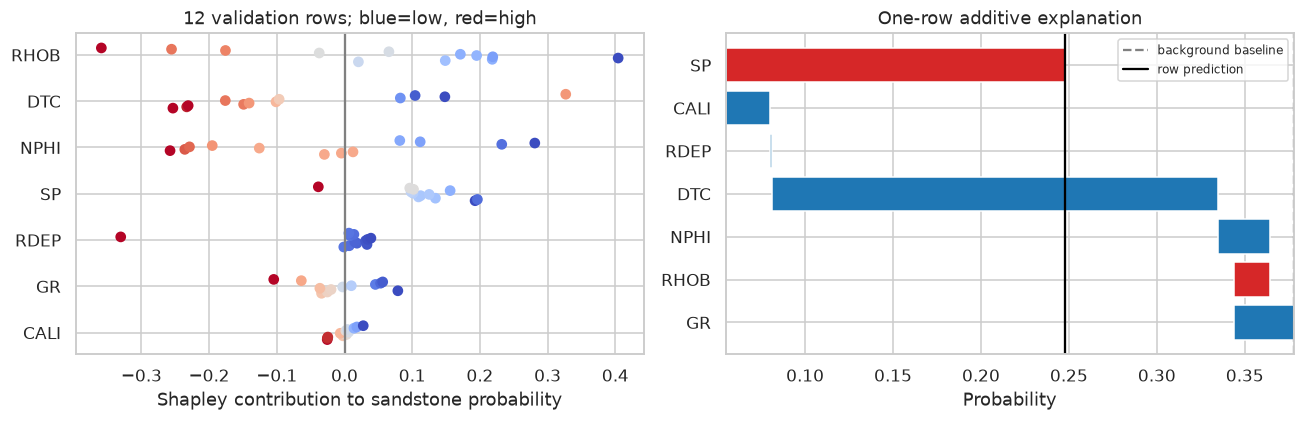

In [9]:
importance=permutation_importance(champion,Xva.to_numpy(),yva,scoring='average_precision',n_repeats=3,random_state=SEED,n_jobs=1)
fig,ax=plt.subplots(figsize=(7,3));order=np.argsort(importance.importances_mean)
ax.barh(np.array(FEATURES)[order],importance.importances_mean[order],xerr=importance.importances_std[order])
ax.set(xlabel='Validation AP decrease',title=f'Permutation importance: {champion_name}');showplot('09_importance')

background=Xtr.sample(16,random_state=SEED).to_numpy()
explain_X=Xva.iloc[np.linspace(0,len(Xva)-1,12,dtype=int)].to_numpy()
def exact_shapley(model, X, background):
    k=X.shape[1]; masks=np.array(list(itertools.product([False,True],repeat=k)))
    values=np.empty((len(X),len(masks)))
    for i,x in enumerate(X):
        mixed=np.where(masks[:,None,:],x[None,None,:],background[None,:,:])
        values[i]=model.predict_proba(mixed.reshape(-1,k))[:,1].reshape(len(masks),len(background)).mean(axis=1)
    lookup={tuple(m):i for i,m in enumerate(masks)}; phi=np.zeros_like(X,dtype=float)
    for j in range(k):
        for index,mask in enumerate(masks):
            if mask[j]: continue
            size=int(mask.sum()); with_j=mask.copy();with_j[j]=True
            weight=math.factorial(size)*math.factorial(k-size-1)/math.factorial(k)
            phi[:,j]+=weight*(values[:,lookup[tuple(with_j)]]-values[:,index])
    baseline=values[:,lookup[tuple([False]*k)]]
    return phi,baseline
shap_values,baseline=exact_shapley(models['logistic'],explain_X,background)
np.testing.assert_allclose(baseline+shap_values.sum(axis=1),models['logistic'].predict_proba(explain_X)[:,1],atol=1e-10)
fig,ax=plt.subplots(1,2,figsize=(12,4))
order=np.argsort(np.abs(shap_values).mean(axis=0))
for rank,j in enumerate(order):
    values=explain_X[:,j]; finite=values[np.isfinite(values)]
    colors=np.nan_to_num(values,nan=np.median(finite) if len(finite) else 0)
    colors=(colors-np.min(colors))/(np.ptp(colors)+1e-9)
    ax[0].scatter(shap_values[:,j],rank+np.linspace(-.15,.15,len(explain_X)),c=colors,cmap='coolwarm',vmin=0,vmax=1)
ax[0].set_yticks(range(len(FEATURES)),np.array(FEATURES)[order]);ax[0].axvline(0,color='gray')
ax[0].set(xlabel='Shapley contribution to sandstone probability',title='12 validation rows; blue=low, red=high')
start=float(baseline[0]); contributions=shap_values[0]
for j,v in enumerate(contributions):
    ax[1].barh(FEATURES[j],v,left=start,color='tab:red' if v>0 else 'tab:blue');start+=v
ax[1].axvline(baseline[0],color='gray',linestyle='--',label='background baseline')
ax[1].axvline(start,color='black',label='row prediction');ax[1].legend(fontsize=8)
ax[1].set(title='One-row additive explanation',xlabel='Probability');showplot('10_shapley')

## 8. Time-series workflow using ThreeWToolkit
Each 3W recording is split in time: first 60% training, next 20% validation, last 20% test, with a 128-row gap at boundaries. At one-second sampling, 128 rows are 128 seconds. Windows never cross recordings or split boundaries. We retain unlabeled rows while windowing, then keep only windows whose **last observed label** is known. This is current-condition detection, not forecasting an event before it begins.

`CleanSignals` examines whole-event means/stds and frozen signals. Its whole-event decision can see future rows, so we demonstrate it as **offline quality analysis only**. For replay, train-fitted mean imputation is causal and uses no future rows. A frozen sensor is not automatically a fault; QGL may legitimately be zero. Missingness/units and operating context need engineering review.

Offline cleaner dropped: ['P-PDG', 'QGL']


,P-TPT,T-TPT,P-MON-CKP,T-JUS-CKP
0,-0.996128,1.002562,-0.979187,1.037908
1,-0.996128,1.002562,-0.976713,1.037066
2,-0.996128,1.002562,-0.974239,1.036225


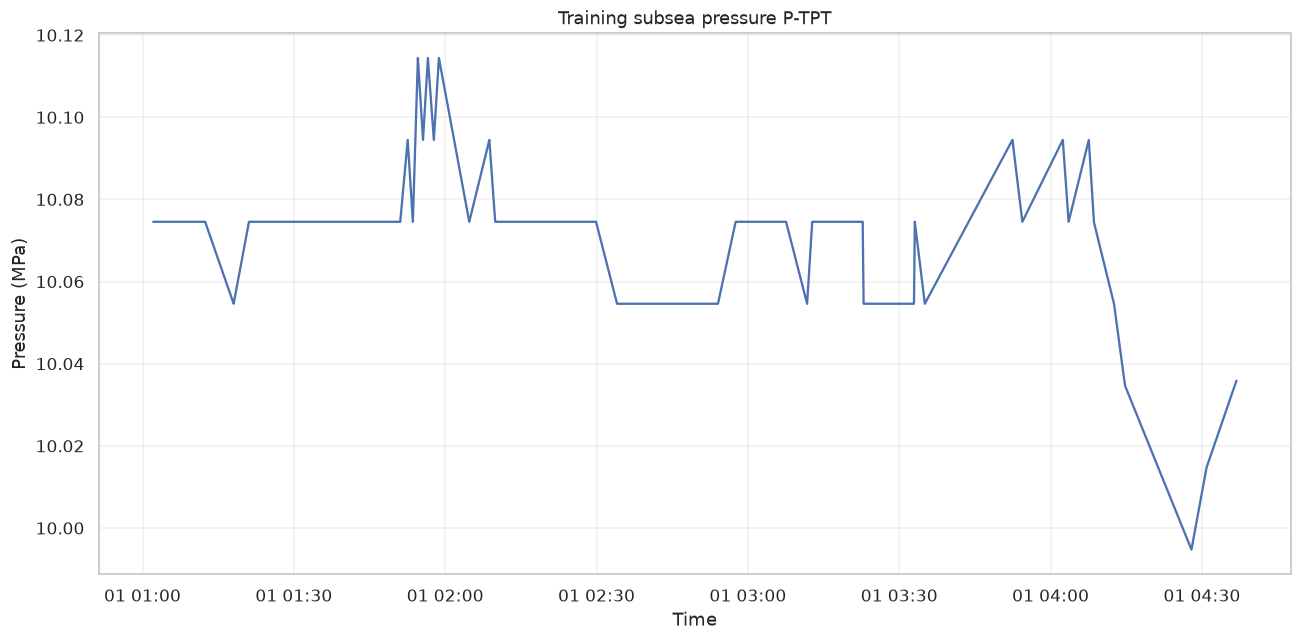

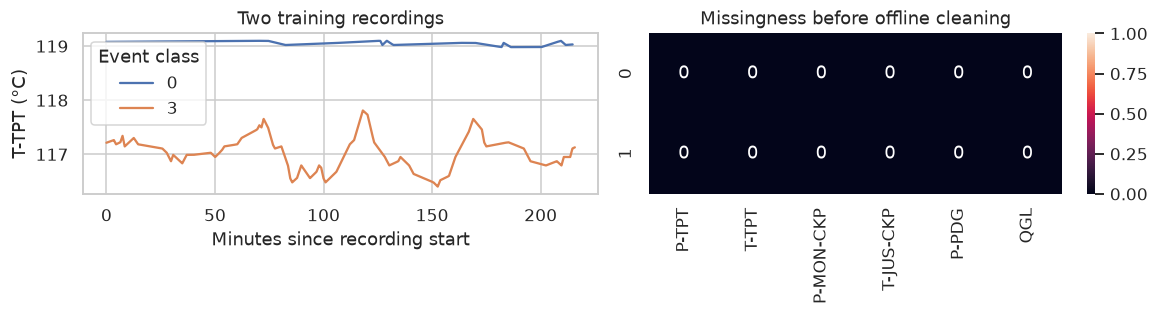

,windows,features
train,145,52
validation,64,52
test,64,52


,mean_P-MON-CKP,mean_P-TPT,mean_T-JUS-CKP,mean_T-TPT,std_P-MON-CKP,std_P-TPT,std_T-JUS-CKP,std_T-TPT,min_P-MON-CKP,min_P-TPT,min_T-JUS-CKP,min_T-TPT,max_P-MON-CKP,max_P-TPT,max_T-JUS-CKP,max_T-TPT,A7_P-MON-CKP,A7_P-TPT,A7_T-JUS-CKP,A7_T-TPT,D7_P-MON-CKP,D7_P-TPT,D7_T-JUS-CKP,D7_T-TPT,D6_P-MON-CKP,D6_P-TPT,D6_T-JUS-CKP,D6_T-TPT,D5_P-MON-CKP,D5_P-TPT,D5_T-JUS-CKP,D5_T-TPT,D4_P-MON-CKP,D4_P-TPT,D4_T-JUS-CKP,D4_T-TPT,D3_P-MON-CKP,D3_P-TPT,D3_T-JUS-CKP,D3_T-TPT,D2_P-MON-CKP,D2_P-TPT,D2_T-JUS-CKP,D2_T-TPT,D1_P-MON-CKP,D1_P-TPT,D1_T-JUS-CKP,D1_T-TPT,A0_P-MON-CKP,A0_P-TPT,A0_T-JUS-CKP,A0_T-TPT
0,1.623888e+06,1.008686e+07,84.291209,119.094641,143941.136319,4083.912242,0.218952,0.000166,1394244.0,10079840.0,83.99593,119.0944,1898820.0,10093880.0,84.72334,119.0949,1.837220e+07,1.141198e+08,953.646172,1347.402048,-618971.047436,-40016.056631,-2.115391,0.001626,832721.250,-14147.50,-0.531025,0.000550,604336.235162,-5002.780477,-0.063564,0.000265,229521.00,-1775.0,0.075955,1.421085e-14,12691.506062,-622.253967,0.029578,0.0,-94896.0,-220.0,0.010460,0.0,-49167.255816,-77.781746,0.003698,0.0,1759754.0,10079840.0,84.06391,119.0949
1,1.538540e+06,1.007762e+07,84.138852,119.095221,89938.573298,1828.855296,0.110401,0.000173,1342556.0,10074540.0,83.90479,119.0949,1742574.0,10081210.0,84.31493,119.0955,1.740660e+07,1.140153e+08,951.922450,1347.408615,-504240.497315,10875.302295,-0.779247,0.001671,183570.500,10686.25,-0.121036,0.000600,117566.755421,3775.950212,0.604787,0.000247,93385.50,1337.5,0.283555,5.000000e-05,34445.292632,470.226009,0.100254,0.0,14198.5,165.0,0.035445,0.0,7876.462436,56.568542,0.012537,0.0,1585894.0,10081210.0,84.29468,119.0955
2,1.580439e+06,1.008660e+07,84.681231,119.095801,135736.861144,3084.138589,0.156869,0.000172,1414892.0,10081300.0,84.31240,119.0955,2042045.0,10091900.0,84.96812,119.0961,1.788063e+07,1.141168e+08,958.058767,1347.415173,-539268.357546,30220.859944,-0.633917,0.001635,-263846.125,10681.25,-0.499634,0.000637,-204381.967257,3779.485745,-0.014817,0.000177,-75674.25,1335.0,-0.004053,1.750000e-04,-26755.152833,473.761543,-0.001432,0.0,-9459.0,165.0,-0.000505,0.0,-3344.615075,63.639610,-0.000177,0.0,1428191.0,10091900.0,84.55823,119.0961


In [10]:
from ThreeWToolkit.preprocessing import CleanSignalsConfig, ImputeMissingConfig, NormalizeConfig
from ThreeWToolkit.dataset import TransformConfig
from ThreeWToolkit.feature_extraction import (WindowingConfig,StatisticalConfig,WaveletConfig,
    SequentialFeatureAdapterConfig,ConcatFeatureAdapterConfig)
SENSORS=['P-TPT','T-TPT','P-MON-CKP','T-JUS-CKP']
segments={k:[] for k in ['train','validation','test']}
for source,g in telemetry.groupby('source_file',sort=True):
    g=g.sort_values('timestamp').reset_index(drop=True)
    dt=pd.to_datetime(g.timestamp).diff().dropna().dt.total_seconds()
    assert dt.eq(1).all(), 'Resample irregular telemetry explicitly before this example'
    a,b=int(len(g)*.6),int(len(g)*.8)
    for name,part in [('train',g.iloc[:a]),('validation',g.iloc[a+128:b]),('test',g.iloc[b+128:])]:
        segments[name].append(part.reset_index(drop=True))
def event(part,columns=SENSORS):
    return DatasetOutputs(signal=part[columns].astype(float).reset_index(drop=True),
        label=part['class'].astype(float).reset_index(drop=True),
        metadata={'event_id':part.source_file.iloc[0],'event_type':'real'})
training_events=FrameDataset([event(p) for p in segments['train']])
quality_events=FrameDataset([event(p,SENSORS+['P-PDG','QGL']) for p in segments['train']])
cleaner=CleanSignalsConfig(average_iqr_threshold=5,std_iqr_threshold=5).build()
cleaner.fit(quality_events)
quality_cleaned=[cleaner.transform(e) for e in quality_events]
print('Offline cleaner dropped:',cleaner.drop_list)
# Training-fitted column scaling demonstration; retain physical units for feature plots.
norm=NormalizeConfig(norm='l2').build();norm.fit(training_events)
display(norm.transform(training_events[0]).signal.head(3))
mean_imputer=ImputeMissingConfig(strategy='mean').build();mean_imputer.fit(training_events)
first=segments['train'][0]
PlotSeries(pd.Series(first['P-TPT'].to_numpy()/1e6,index=pd.to_datetime(first.timestamp)),
    title='Training subsea pressure P-TPT',xlabel='Time',ylabel='Pressure (MPa)').plot();showplot('11_pressure')
fig,ax=plt.subplots(1,2,figsize=(11,3))
for p in segments['train']:
    ax[0].plot(np.arange(len(p))/60,p['T-TPT'],label=p.source_file.iloc[0].split('/')[0])
ax[0].set(xlabel='Minutes since recording start',ylabel='T-TPT (°C)',title='Two training recordings');ax[0].legend(title='Event class')
q=pd.concat([e.signal.isna().mean() for e in quality_events],axis=1)
sns.heatmap(q.T,ax=ax[1],vmin=0,vmax=1,annot=True);ax[1].set_title('Missingness before offline cleaning')
showplot('12_multisignal_quality')
feature_config=SequentialFeatureAdapterConfig(steps=[
    WindowingConfig(window_size=128,overlap=0,pad_start=False,label_strategy='last'),
    ConcatFeatureAdapterConfig(steps=[StatisticalConfig(features=['mean','std','min','max']),
                                    WaveletConfig(wavelet='haar',level=7,full=False)])])
transform=TransformConfig(pre_processing=ImputeMissingConfig(strategy='mean'),feature_extraction=feature_config).build()
transform.fit(training_events)
window_data={}; window_context={}
for split,parts in segments.items():
    feature_parts=[];labels=[];context=[]
    for part in parts:
        out=transform.transform_event(event(part))
        ends=np.arange(127,len(part),128)
        assert len(out.signal)==len(ends)
        known=out.label.notna().to_numpy()
        feature_parts.append(out.signal.loc[known].reset_index(drop=True))
        labels.append((out.label.loc[known].to_numpy()==3).astype(int))
        context.append(part.iloc[ends[known]][['id','timestamp','source_file','P-TPT']].reset_index(drop=True))
    window_data[split]=(pd.concat(feature_parts,ignore_index=True),np.concatenate(labels))
    window_context[split]=pd.concat(context,ignore_index=True)
display(pd.DataFrame({k:{'windows':len(v[0]),'features':v[0].shape[1]} for k,v in window_data.items()}).T)
display(window_data['train'][0].head(3))

### Window statistics, wavelets, spectrum and clustering
The feature adapter concatenates means/std/min/max and Haar wavelet coefficients. This toolkit wavelet implementation applies impulse-response filters at each window endpoint; these columns are not a full wavelet spectrogram. The separate PyWavelets CWT plot below shows frequency content over a complete window.

Shape clustering uses 24 disjoint 256-second training snippets, downsampled to 64 points, z-normalized per snippet, then DTW distances and hierarchical linkage. This deliberately removes pressure level to compare **shape**. Clusters have no automatic physical diagnosis. Per-snippet normalization is retrospective; an online detector must wait for its trailing window. No cluster number or threshold is chosen using test labels.

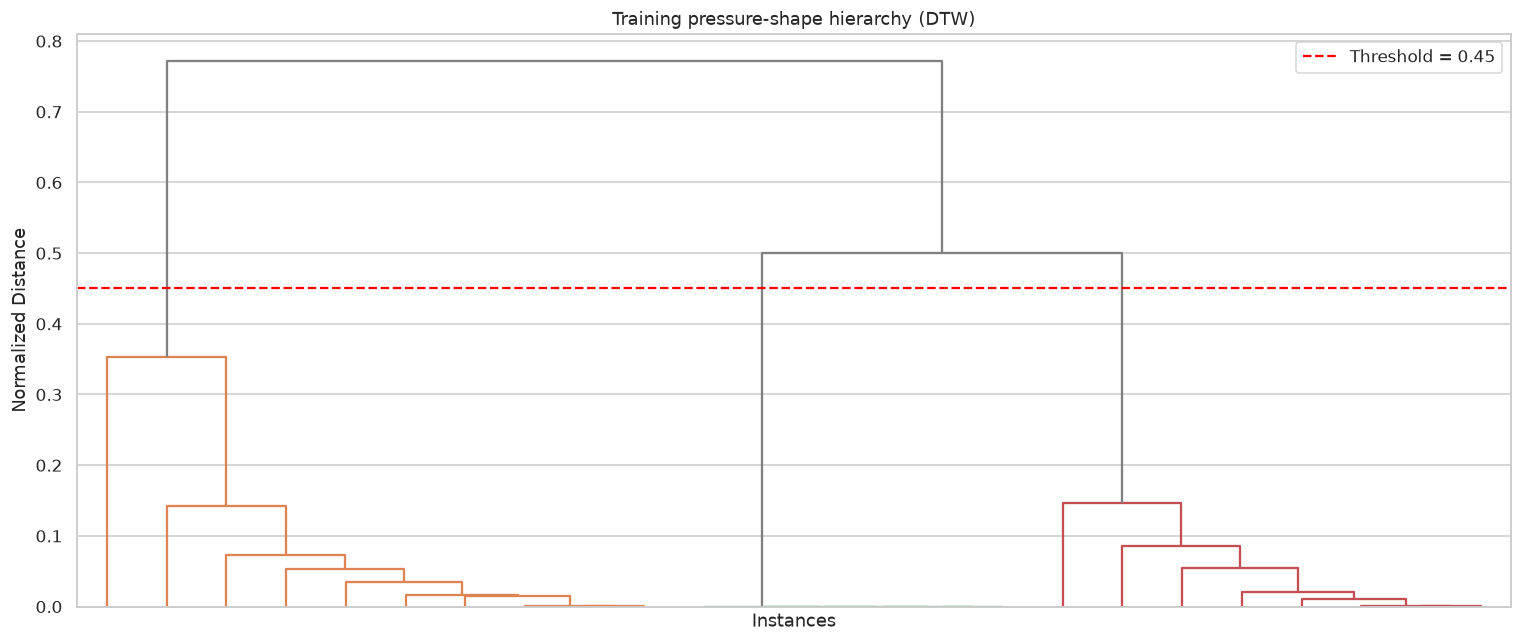

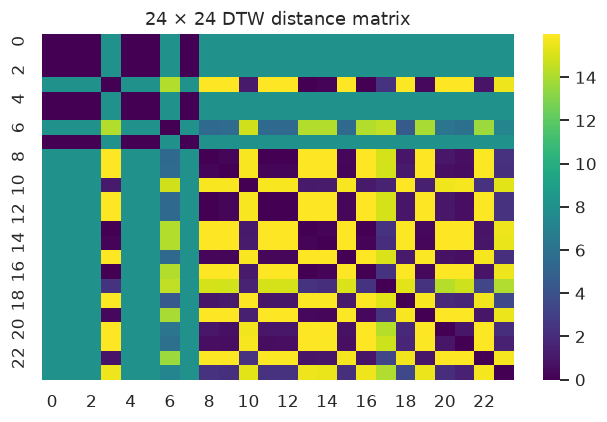

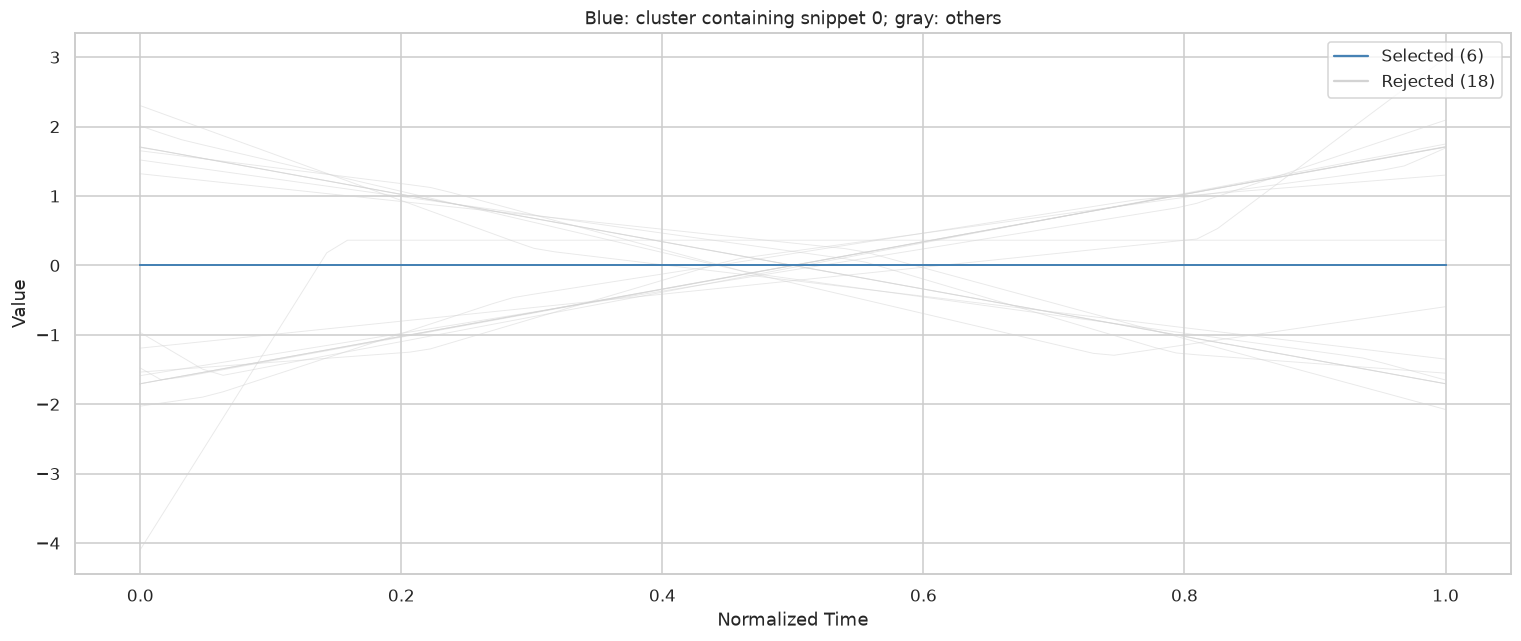

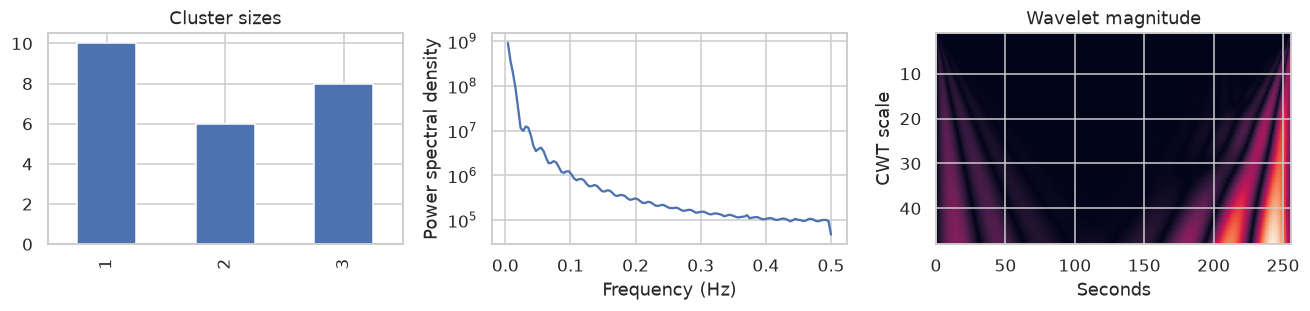

In [11]:
import pywt
from scipy.signal import periodogram
from ThreeWToolkit.clustering import TimeSeriesScaler,TimeSeriesResampler,DistanceComputer,HierarchicalClusterer
from ThreeWToolkit.core.base_clustering import (TimeSeriesScalingConfig,ResamplingConfig,DistanceMatrixConfig,HierarchicalClusteringConfig)
from ThreeWToolkit.data_visualization.clustering_plots import DendrogramPlot,ClusteringOverlayPlot
snippets=[]
for part in segments['train']:
    x=part['P-TPT'].to_numpy(dtype=float)
    for start in np.linspace(0,len(x)-256,12,dtype=int): snippets.append(x[start:start+256])
short=TimeSeriesResampler(ResamplingConfig(step_size=4,step_method='mean')).fit_transform(snippets)
shapes=TimeSeriesScaler(TimeSeriesScalingConfig()).fit_transform(short)
distance=DistanceComputer(DistanceMatrixConfig(metric='dtw',n_jobs=1)).fit_transform(shapes)
clusterer=HierarchicalClusterer(HierarchicalClusteringConfig(linkage_method='average')).fit(distance)
cluster_ids=clusterer.get_clusters_at_threshold(.45)
DendrogramPlot(clusterer.linkage_matrix_,threshold=.45,title='Training pressure-shape hierarchy (DTW)').plot();showplot('13_dendrogram')
fig,ax=plt.subplots(figsize=(6,4));sns.heatmap(distance,ax=ax,cmap='viridis');ax.set_title('24 × 24 DTW distance matrix');showplot('14_distance_heatmap')
selected=np.flatnonzero(cluster_ids==cluster_ids[0]).tolist()
ClusteringOverlayPlot(shapes,selected_indices=selected,title='Blue: cluster containing snippet 0; gray: others').plot();showplot('15_cluster_overlay')
fig,ax=plt.subplots(1,3,figsize=(12,3))
pd.Series(cluster_ids).value_counts().sort_index().plot.bar(ax=ax[0],title='Cluster sizes')
freq,power=periodogram(snippets[-1],fs=1,detrend='linear')
ax[1].semilogy(freq[1:],power[1:]);ax[1].set(xlabel='Frequency (Hz)',ylabel='Power spectral density')
coeff,f=pywt.cwt(snippets[-1]-np.mean(snippets[-1]),np.arange(1,49),'morl',sampling_period=1)
ax[2].imshow(np.abs(coeff),aspect='auto',extent=[0,256,48,1]);ax[2].set(xlabel='Seconds',ylabel='CWT scale',title='Wavelet magnitude')
showplot('16_clusters_and_spectrum')

## 9. Detect and replay historical telemetry
A small forest learns window features. **These scores are confounded by recording identity** and are not comparable to held-out-well FORCE performance. Replay uses only a complete trailing 128-second window plus the frozen training transform. We verify replay/batch parity, attach event time and source ID, and export probabilities for a dashboard. A real worker would receive records, buffer by well, enforce ordering/watermarks, and score at window completion. This finite local replay does not connect to a live well.

Within-recording demonstration ONLY: {'accuracy': 1.0, 'balanced_accuracy': 1.0, 'precision': 1.0, 'recall_sensitivity': 1.0, 'f1': 1.0, 'MCC': 1.0, 'ROC_AUC': 1.0, 'average_precision': 1.0}


**Interpretation:** recordings have different pressure/temperature levels and each has only one known class. Perfect separation can identify the recording rather than learn a general slugging mechanism. Obtain many normal/abnormal events across wells before deployment.

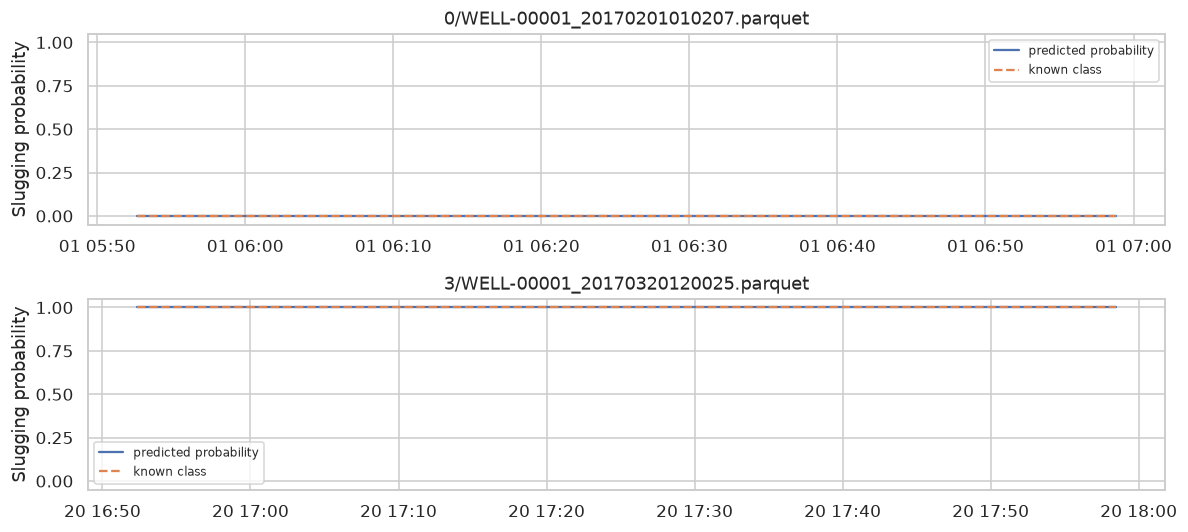

In [12]:
Xt,yt=window_data['train']; Xv,yv=window_data['validation']; Xe,ye=window_data['test']
time_trainer=SklearnTrainerConfig(config_model=SklearnModelsConfig(model_type=RandomForestClassifier,
    model_params={'n_estimators':80,'max_depth':5,'min_samples_leaf':3,'random_state':SEED}),n_jobs=2).build()
time_result=time_trainer.train(frames(Xt,yt),frames(Xv,yv))
time_model=time_result.model.model
p_window=time_model.predict_proba(Xe.to_numpy())[:,1]
print('Within-recording demonstration ONLY:',metrics(ye,p_window))
display(Markdown('**Interpretation:** recordings have different pressure/temperature levels and each '
    'has only one known class. Perfect separation can identify the recording rather than learn a '
    'general slugging mechanism. Obtain many normal/abnormal events across wells before deployment.'))
replayed=[]
for part in segments['test']:
    for start in range(0,len(part)-127,128):
        batch=part.iloc[start:start+128]
        # In real replay, this cell runs after all 128 records have arrived.
        features=transform.transform_event(event(batch))
        if pd.notna(features.label.iloc[0]):
            replayed.append(float(time_model.predict_proba(features.signal.to_numpy())[0,1]))
np.testing.assert_allclose(replayed,p_window)
replay=window_context['test'].copy()
replay['actual_slugging']=ye;replay['probability_slugging']=replayed
replay['predicted_slugging']=(replay.probability_slugging>=.5).astype(int)
replay['model_version']='threew_demo_v1'
replay.to_csv(ART/'telemetry_predictions.csv',index=False)
fig,axes=plt.subplots(2,1,figsize=(11,5))
for ax,(source,g) in zip(axes,replay.groupby('source_file',sort=True)):
    ax.plot(pd.to_datetime(g.timestamp),g.probability_slugging,label='predicted probability')
    ax.plot(pd.to_datetime(g.timestamp),g.actual_slugging,'--',label='known class')
    ax.set(title=source,ylim=(-.05,1.05),ylabel='Slugging probability');ax.legend(fontsize=8)
showplot('17_replay_predictions')

## 10. Regression, learning curves and residuals
A separate regression exercise estimates GR from the other six logs. GR is removed from inputs; lithology labels are never predictors. This demonstrates missing-log reconstruction, not forecasting production. Compare a training-mean baseline, MAE in gAPI and R² on the held-out well. R² can be negative if the model is worse than predicting that test set's mean.

The learning curve uses increasing training samples but the **same validation well**; it is a development diagnostic, not independent test evidence. A large train/validation gap suggests overfitting or well shift. No extra test-based tuning follows these figures.

,R2,MAE_gAPI
forest,-2.361543,18.742134
training_mean,-0.137059,9.027347


**Reject this regression model for deployment:** it is worse than the training-mean baseline on this held-out well. Investigate well shift, missing sensors and a physically justified feature set using development wells; reserve a new final test for the next experiment.

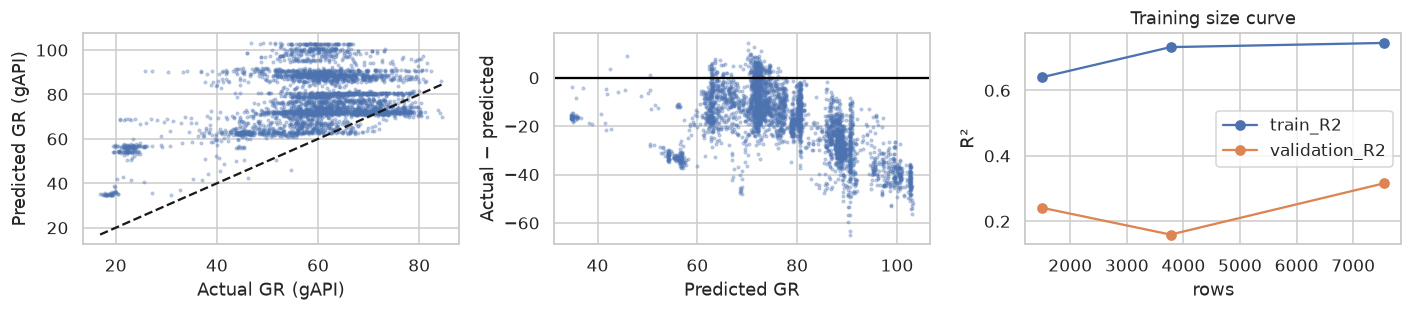

In [13]:
REG_FEATURES=[f for f in FEATURES if f!='GR']
rtrain=train.dropna(subset=['GR']);rval=val.dropna(subset=['GR']);rtest=test.dropna(subset=['GR'])
regressor=make_pipeline(RandomForestRegressor(n_estimators=80,max_depth=10,min_samples_leaf=8,n_jobs=2,random_state=SEED))
regressor.fit(rtrain[REG_FEATURES],rtrain.GR)
rpred=regressor.predict(rtest[REG_FEATURES]); residual=rtest.GR.to_numpy()-rpred
baseline_reg=DummyRegressor().fit(rtrain[REG_FEATURES],rtrain.GR).predict(rtest[REG_FEATURES])
reg_scores=pd.DataFrame({'forest':{'R2':r2_score(rtest.GR,rpred),'MAE_gAPI':mean_absolute_error(rtest.GR,rpred)},
    'training_mean':{'R2':r2_score(rtest.GR,baseline_reg),'MAE_gAPI':mean_absolute_error(rtest.GR,baseline_reg)}}).T
display(reg_scores)
if reg_scores.loc['forest','MAE_gAPI'] > reg_scores.loc['training_mean','MAE_gAPI']:
    display(Markdown('**Reject this regression model for deployment:** it is worse than the training-mean '
        'baseline on this held-out well. Investigate well shift, missing sensors and a physically justified '
        'feature set using development wells; reserve a new final test for the next experiment.'))
learning=[]
for fraction in [.2,.5,1.]:
    sample=rtrain.sample(frac=fraction,random_state=SEED)
    fitted=clone(regressor).fit(sample[REG_FEATURES],sample.GR)
    learning.append({'rows':len(sample),'train_R2':fitted.score(sample[REG_FEATURES],sample.GR),
                    'validation_R2':fitted.score(rval[REG_FEATURES],rval.GR)})
fig,ax=plt.subplots(1,3,figsize=(13,3))
ax[0].scatter(rtest.GR,rpred,s=3,alpha=.3);limits=[rtest.GR.min(),rtest.GR.max()]
ax[0].plot(limits,limits,'k--');ax[0].set(xlabel='Actual GR (gAPI)',ylabel='Predicted GR (gAPI)')
ax[1].scatter(rpred,residual,s=3,alpha=.3);ax[1].axhline(0,color='black');ax[1].set(xlabel='Predicted GR',ylabel='Actual − predicted')
pd.DataFrame(learning).set_index('rows').plot(ax=ax[2],marker='o');ax[2].set(ylabel='R²',title='Training size curve')
showplot('18_regression')

## 11. Save, reload, predict and hand off
A deployable artifact includes **preprocessing + model + ordered features + label meaning + versions + data hashes + validation policy**. The sklearn Pipeline has portable built-in components. Toolkit wrappers are also saved/reloaded; PyTorch saving retains its architecture/config. Load pickle/torch artifacts only from trusted sources.

`log_predictions.csv` is a Power BI-ready held-out-well result with depth, class, probability and stable row ID. `telemetry_predictions.csv` has timestamps and a different target. Never join them as if they measured the same event. HTML is an optional study export, not a model service.

In [14]:
MODEL_VERSION='force_sandstone_v1'
joblib.dump(champion,ART/'sandstone_pipeline.joblib')
loaded=joblib.load(ART/'sandstone_pipeline.joblib')
np.testing.assert_allclose(loaded.predict_proba(Xte.iloc[:20].to_numpy())[:,1],p_test[:20])
ModelRecorder.save_model(training['forest'][1].model,ART/'toolkit_forest.pkl')
reloaded_forest=ModelRecorder.load_model(ART/'toolkit_forest.pkl')
np.testing.assert_array_equal(reloaded_forest.model.predict(Xte.iloc[:20].to_numpy()),models['forest'].predict(Xte.iloc[:20].to_numpy()))
ModelRecorder.save_model(neural_result.model,ART/'toolkit_mlp.pt')
reloaded_mlp=ModelRecorder.load_model(ART/'toolkit_mlp.pt');reloaded_mlp.eval()
with torch.inference_mode():
    restored_prob=torch.softmax(reloaded_mlp(torch.tensor(Zte[:20],dtype=torch.float32)),dim=1).numpy()[:,1]
np.testing.assert_allclose(restored_prob,test_prob['MLP'][:20],rtol=1e-5,atol=1e-6)
joblib.dump(neural_pre,ART/'mlp_preprocessing.joblib')
ModelRecorder.save_transform(transform,ART/'telemetry_transform.pkl')
ModelRecorder.save_model(time_result.model,ART/'telemetry_forest.pkl')
restored_transform=ModelRecorder.load_transform(ART/'telemetry_transform.pkl')
pd.testing.assert_frame_equal(restored_transform.transform_event(event(segments['test'][0].iloc[:128])).signal,
                             transform.transform_event(event(segments['test'][0].iloc[:128])).signal)
log_predictions=test[['id','WELL','DEPTH_MD']].copy()
log_predictions['actual_sandstone']=yte;log_predictions['probability_sandstone']=p_test
log_predictions['predicted_sandstone']=pred_test;log_predictions['model_version']=MODEL_VERSION
log_predictions.to_csv(ART/'log_predictions.csv',index=False)
validation_table.to_csv(ART/'validation_metrics.csv');test_table.to_csv(ART/'test_metrics.csv')
trial_table.to_json(ART/'tuning_trials.json',orient='records',indent=2)
manifest={'model_version':MODEL_VERSION,'champion':champion_name,'target':'lithology code 30000 vs other',
    'features':FEATURES,'train_wells':TRAIN_WELLS,'validation_wells':VAL_WELLS,'test_wells':TEST_WELLS,
    'threshold':.5,'seed':SEED,'tuning_engine':tuning_engine,
    'versions':{p:importlib.metadata.version(p) for p in ['numpy','pandas','scikit-learn','torch']},
    'data_sha256':{f:hashlib.sha256((ROOT/'data'/f).read_bytes()).hexdigest() for f in ['force2020_logs.parquet','threew_real_events.parquet']},
    'limitations':['one final test well','binary lithology reduction','3W class confounded with recording'],
    'cloud_deployed':False,'regression_deployment':'rejected if worse than baseline; not deployed'}
(ART/'model_card.json').write_text(json.dumps(manifest,indent=2))
print('All local reload and replay parity checks passed. Artifacts:',ART.relative_to(ROOT))
display(log_predictions.head())

All local reload and replay parity checks passed. Artifacts: .cache/oilfield_ml


,id,WELL,DEPTH_MD,actual_sandstone,probability_sandstone,predicted_sandstone,model_version
55071,force2020:55071,16/1-6 A,1175.979735,0,0.017835,0,force_sandstone_v1
55072,force2020:55072,16/1-6 A,1176.131735,0,0.019222,0,force_sandstone_v1
55073,force2020:55073,16/1-6 A,1176.283735,0,0.015857,0,force_sandstone_v1
55074,force2020:55074,16/1-6 A,1176.435735,0,0.015857,0,force_sandstone_v1
55075,force2020:55075,16/1-6 A,1176.587735,0,0.018277,0,force_sandstone_v1


## 12. Production design and Snowflake hand-off

```text
Files / vendor API ── dlt ingestion ───────────────────┐
Telemetry ── Kafka ── Spark (event-time windows) ──────┤
                                                     ▼
                                               Snowflake RAW
                                                     │ dbt: tested feature contracts
                                                     ▼
                                            ANALYTICS feature tables
                                                     │ frozen model version
                                                     ▼
                                            ANALYTICS predictions
                                                     │
                                            Power BI / Streamlit
Airflow: orchestrates bounded ingestion → dbt → scoring → validation jobs
```

Airflow/Kafka and our Spark scripts run outside Snowflake in this workspace. dbt runs locally but executes SQL in Snowflake. Training and serving do not have to use the same runtime. Snowflake Model Registry can store the sklearn pipeline and execute warehouse inference; an online REST model service is a separate deployment. See [Snowflake registry](https://docs.snowflake.com/en/developer-guide/snowflake-ml/model-registry/overview) and [inference](https://docs.snowflake.com/en/developer-guide/snowflake-ml/inference/native-batch-inference-sql).

**Operational contract:** keep `(source_id,event_id,model_version)` unique; MERGE scored batches for retries. Retain source cursor/Kafka offsets and checkpoints. Handle duplicates, late arrivals, backfills and deletes explicitly. Monitor input null rates, drift, latency, failed loads and model error when delayed labels arrive. Quarantine incompatible schemas; never silently impute a completely absent required column. Train on historical data, approve a version, score new rows with that frozen version; do not retrain every incoming event.

**What has run:** local reads, training, evaluation, replay and persistence. **What has not:** Snowflake registry upload, remote inference, continuous workers or a refreshed Power BI service. No cloud operations occur on Run All.

In [15]:
# Optional cloud exercise. Change this only after reviewing the prerequisites below.
RUN_CLOUD = False
if RUN_CLOUD:
    import snowflake.connector
    from snowflake.snowpark import Session
    from snowflake.ml.registry import Registry
    from Snowflake.connection import read_profile, connector_options
    settings=read_profile()
    connection=snowflake.connector.connect(**connector_options(settings))
    session=Session.builder.config('connection',connection).create()
    try:
        registry=Registry(session=session,database_name=settings['database'],schema_name='ANALYTICS')
        version=registry.log_model(champion,model_name='FORCE_SANDSTONE',version_name='V1',
            sample_input_data=Xtr.iloc[:10].copy(),
            target_platforms=['WAREHOUSE'],
            comment='Educational binary sandstone classifier; one held-out test well')
        display(version.show_functions())
        # Small remote smoke test. A real job scores a Snowpark feature table by stable ID.
        remote=version.run(Xte.iloc[:5].copy(),function_name='predict_proba')
        display(remote)
    finally:
        session.close();connection.close()
else:
    print('Cloud exercise skipped: local study is complete without Snowflake.')

Cloud exercise skipped: local study is complete without Snowflake.


### Optional: publish the already computed predictions
This is a separate, **off-by-default** data upload using the installed Snowflake connector; it does not require Model Registry. It creates one analytics table and MERGEs a bounded batch using `(ID, MODEL_VERSION)`. This demonstrates a dashboard hand-off, not remote model serving. The role needs CREATE TABLE and write privileges. No passwords are displayed.

In [16]:
PUBLISH_PREDICTIONS = False
if PUBLISH_PREDICTIONS:
    from Snowflake.connection import connect
    from snowflake.connector.pandas_tools import write_pandas
    upload=log_predictions.copy();upload.columns=upload.columns.str.upper()
    assert not upload.duplicated(['ID','MODEL_VERSION']).any()
    assert upload.PROBABILITY_SANDSTONE.between(0,1).all()
    with connect() as connection:
        with connection.cursor() as cursor:
            cursor.execute("""CREATE TABLE IF NOT EXISTS ANALYTICS.ML_LOG_PREDICTIONS (
                ID VARCHAR, WELL VARCHAR, DEPTH_MD FLOAT, ACTUAL_SANDSTONE INTEGER,
                PROBABILITY_SANDSTONE FLOAT, PREDICTED_SANDSTONE INTEGER,
                MODEL_VERSION VARCHAR, SCORED_AT TIMESTAMP_LTZ DEFAULT CURRENT_TIMESTAMP())""")
            success,chunks,count,_=write_pandas(connection,upload,'ML_LOG_PREDICTIONS_STAGE',
                schema='ANALYTICS',auto_create_table=True,table_type='temporary')
            assert success and count==len(upload)
            cursor.execute("""MERGE INTO ANALYTICS.ML_LOG_PREDICTIONS t
                USING ANALYTICS.ML_LOG_PREDICTIONS_STAGE s
                ON t.ID=s.ID AND t.MODEL_VERSION=s.MODEL_VERSION
                WHEN MATCHED THEN UPDATE SET
                    t.WELL=s.WELL, t.DEPTH_MD=s.DEPTH_MD,
                    t.ACTUAL_SANDSTONE=s.ACTUAL_SANDSTONE,
                    t.PROBABILITY_SANDSTONE=s.PROBABILITY_SANDSTONE,
                    t.PREDICTED_SANDSTONE=s.PREDICTED_SANDSTONE
                WHEN NOT MATCHED THEN INSERT
                    (ID,WELL,DEPTH_MD,ACTUAL_SANDSTONE,PROBABILITY_SANDSTONE,PREDICTED_SANDSTONE,MODEL_VERSION)
                VALUES (s.ID,s.WELL,s.DEPTH_MD,s.ACTUAL_SANDSTONE,s.PROBABILITY_SANDSTONE,s.PREDICTED_SANDSTONE,s.MODEL_VERSION)""")
            print('Prediction batch merged; select ANALYTICS.ML_LOG_PREDICTIONS in Power BI.')
else:
    print('Prediction upload skipped; local CSVs are ready for Power BI.')

Prediction upload skipped; local CSVs are ready for Power BI.


### Before enabling the cloud cell

1. Run `python Snowflake/connection.py --dbt debug`; configure existing `COMPUTE_WH` and `INTERVIEW_DB` first. Reuse local credentials; never paste them into this notebook. A scheduled worker requires unattended authentication.
2. In the **same `.venv`**, install a compatible `snowflake-ml-python` with `python -m pip install snowflake-ml-python`, then `python -m pip check`. This optional package is **not installed or verified here**. Python 3.14/local sklearn versions may be unsupported by a registry warehouse runtime. Resolve the documented runtime/package compatibility before uploading; do not claim a local pickle will automatically run remotely. Do not alter the shared environment blindly if resolution conflicts; use a supported Snowflake-managed training runtime for the optional cloud exercise instead.
3. The role needs warehouse/database/schema USAGE and CREATE MODEL on the target schema; an existing model needs appropriate privileges. `V1` is a new version, not an overwrite instruction. Use a new explicit version for another experiment and promote only after remote parity checks.
4. For real rows, read `RAW.FORCE2020_LOGS` after loading its ingestion config; build a dbt view selecting the seven numeric features and preserving `ID`. Validate identical column names, order, units and imputation behavior. dbt's generic event starter is **not already a well-log feature model**.
5. Run versioned inference on a small batch, compare with local scores, then MERGE outputs into `ANALYTICS.ML_PREDICTIONS` by event ID/model version. For frequent scoring choose a single scheduler (Airflow microbatch or Snowflake task/stream), with a watermark; don't enable both writers. For true low-latency serving, provision the separate service described in Snowflake's documentation. Warehouse queries are not a permanently running REST endpoint.
6. Power BI connects to the resulting prediction table via its Snowflake connector; see [PowerBI/README.md](PowerBI/README.md). Import needs refresh; DirectQuery queries Snowflake on report interaction and still has caching/refresh behavior. Neither mode is an automatic per-second dashboard.

### Toolkit map: where to keep learning

| Package used here | Where it appears | Reference |
|---|---|---|
| core, dataset | FrameDataset, DatasetOutputs, TransformConfig | [API guide](ThreeWToolkit/AGENTS.md) |
| preprocessing | CleanSignals, ImputeMissing, Normalize | [source](ThreeWToolkit/preprocessing/) |
| feature_extraction | window → statistical + wavelet adapters | [source](ThreeWToolkit/feature_extraction/) |
| models, trainer | sklearn Pipeline wrappers; TorchTrainer/MLP | [source](ThreeWToolkit/trainer/) |
| assessment, metrics | toolkit label assessment + sklearn probability diagnostics | [source](ThreeWToolkit/assessment/) |
| clustering, visualization | DTW hierarchy, overlay, series, correlation | [source](ThreeWToolkit/clustering/) |
| utils | sklearn/torch/transform persistence and parity checks | [source](ThreeWToolkit/utils/model_recorder.py) |

Advanced items to add only when justified: multiclass lithology, domain-specific loss, more held-out wells, LSTM/temporal CNN for ordered windows, distributed feature computation, concept drift and calibrated alert thresholds. More models do not compensate for weak validation.

**Your interview explanation:** “I fixed the target and split by well before fitting preprocessing; compared a baseline, classical models and an MLP; tuned only on development wells; reported the untouched test result and limitations; serialized preprocessing with the model; verified reload/replay parity; designed versioned, idempotent inference and dashboard outputs.”



Upstream examples for deeper reading (their full-dataset assumptions differ from our local extracts):
[sklearn training](../Stage_1_learn_data/3W/toolkit/demos/sklearn_models_examples.ipynb),
[MLP training](../Stage_1_learn_data/3W/toolkit/demos/mlp_timeseries_example.ipynb),
[cleaning](../Stage_1_learn_data/3W/toolkit/demos/data_cleaning_examples.ipynb),
[feature extraction](../Stage_1_learn_data/3W/toolkit/demos/feature_extraction_examples.ipynb),
[clustering](../Stage_1_learn_data/3W/toolkit/demos/clustering_pipeline_examples.ipynb),
[metrics](../Stage_1_learn_data/3W/toolkit/demos/using_metrics.ipynb), and
[persistence](../Stage_1_learn_data/3W/toolkit/demos/load_save_model_examples.ipynb).

### Your next experiment
Write the hypothesis, what changes, which split selects it, and the expected failure mode before coding. Keep the final test set out of iteration.

In [17]:
# Your experiment cell — keep the starter notebook available for the actual assessment.